# Phase 2: Exploratory Data Analysis

**Business question this phase serves:** *which rating factors actually move claim frequency and
claim severity, and how?* This is the analysis that justifies every factor that goes into the GLM/GAM
in Phase 4-6: a factor earns its place in the pricing model by showing a real, exposure-weighted
relationship with risk here, not by being available in the file.

**Input:** [`data/processed/policy_level_clean.parquet`](../data/processed/policy_level_clean.parquet),
built in [Phase 1](01_data_acquisition_and_quality_checks.ipynb).

**What this notebook does:**
1. Portfolio-level KPIs, and a worked example of *why* claim frequency must be computed
   exposure-weighted, not as a plain row average.
2. The shape of the exposure distribution itself.
3. A univariate risk profile, exposure-weighted frequency and average severity, for every
   candidate rating factor.
4. A correlation / redundancy check across the continuous factors, to flag multicollinearity risk
   before it becomes a GLM stability problem in Phase 4.
5. A short synthesis: which factors look like frequency drivers, which look like severity drivers,
   and why we model the two separately.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda.profiling import (
    weighted_frequency_by_factor,
    severity_by_factor,
    bin_continuous,
    plot_frequency_severity_profile,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "policy_level_clean.parquet")
print(f"Loaded {len(df):,} policies, {df.shape[1]} columns.")

Loaded 668,626 policies, 18 columns.


## 1. Portfolio overview, and why frequency must be exposure-weighted

The single most common mistake in a first pass at insurance EDA is computing average claim frequency
as `ClaimNb.mean()`: a plain row average. That treats a policy on risk for 2 weeks exactly the same
as one on risk for the full year, which is wrong: a policy with tiny exposure has had almost no chance
to claim, so it silently drags a naive average down. The correct estimator sums claims and sums
exposure separately, then divides:

$$\text{frequency} = \frac{\sum \text{claims}}{\sum \text{exposure}}$$

The cell below computes both, on this exact portfolio, to make the size of the mistake concrete rather
than abstract.

In [2]:
total_exposure = df["Exposure"].sum()
total_claims = df["ClaimNb_freq_target"].sum()

naive_frequency = df["ClaimNb_freq_target"].mean()          # WRONG: plain row average
weighted_frequency = total_claims / total_exposure           # CORRECT: exposure-weighted

paid = df.loc[df["HasPaidClaim"]]
overall_severity = paid["sev_claim_amount"].sum() / paid["sev_claim_count"].sum()
pure_premium = weighted_frequency * overall_severity

print(f"Total exposure                    : {total_exposure:,.1f} policy-years")
print(f"Total claims                      : {total_claims:,}")
print(f"Naive row-average 'frequency'     : {naive_frequency:.4f}  <-- WRONG estimator")
print(f"Exposure-weighted frequency       : {weighted_frequency:.4f}  <-- CORRECT estimator")
print(f"Understatement from the naive estimator : {weighted_frequency / naive_frequency:.2f}x")
print()
print(f"Overall average severity (paid claims only) : EUR {overall_severity:,.0f}")
print(f"Overall pure premium (frequency x severity)  : EUR {pure_premium:,.1f} per policy-year")

Total exposure                    : 353,559.9 policy-years
Total claims                      : 26,160
Naive row-average 'frequency'     : 0.0391  <-- WRONG estimator
Exposure-weighted frequency       : 0.0740  <-- CORRECT estimator
Understatement from the naive estimator : 1.89x

Overall average severity (paid claims only) : EUR 2,267
Overall pure premium (frequency x severity)  : EUR 167.8 per policy-year


**Finding.** The plain row average of `ClaimNb` (3.9%) is a number of claims per policy, not a
frequency: it ignores how long each policy was on risk. Dividing total claims by total exposure gives
the claim frequency, **7.40% per policy-year**, 1.89 times higher. The reason is visible in the exposure
distribution below: a large share of policies have short exposure (median 0.49 years). Every frequency
number in the rest of this notebook uses the exposure-weighted estimator, via
`src/eda/profiling.weighted_frequency_by_factor`, one shared function used everywhere.

## 2. Exposure distribution

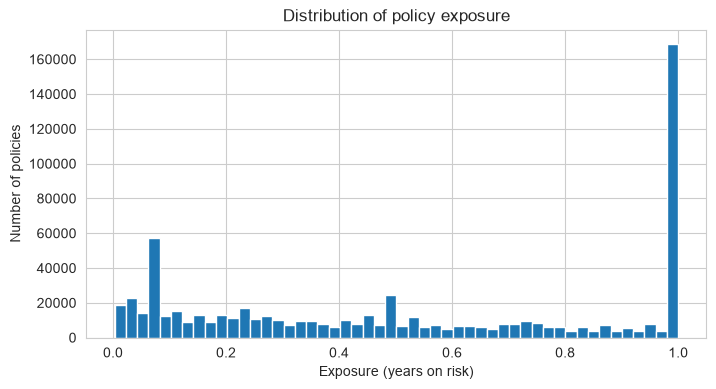

,Exposure quantile
0.0000,0.0027
0.1000,0.0700
0.2500,0.1800
0.5000,0.4900
0.7500,0.9900
0.9000,1.0000
1.0000,1.0000


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Exposure"], bins=50, color="#1f77b4", edgecolor="white")
ax.set_xlabel("Exposure (years on risk)")
ax.set_ylabel("Number of policies")
ax.set_title("Distribution of policy exposure")
plt.show()

display(df["Exposure"].quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]).to_frame("Exposure quantile"))

**Finding.** The portfolio is dominated by partial-year exposures: the median policy is on risk
for **0.49 years** (about 6 months), a quarter of policies have less than **0.18 years** (~2 months),
and only 10% reach a full year. This is exactly what makes the naive-vs-weighted gap in Section 1 so
large, and it's a strong argument for always sanity-checking any "average X per policy" statistic
against its exposure-weighted counterpart before trusting it.

## 3. Univariate risk profiles

For each candidate rating factor: exposure-weighted frequency (blue line, left axis) with each
category's share of total portfolio exposure shown as a gray bar in the background (a dramatic
frequency swing backed by 0.1% of the book is a different story than one backed by 20% of it), and
average paid severity (red bars, right panel).

### 3.1 `Area`: density-tier code

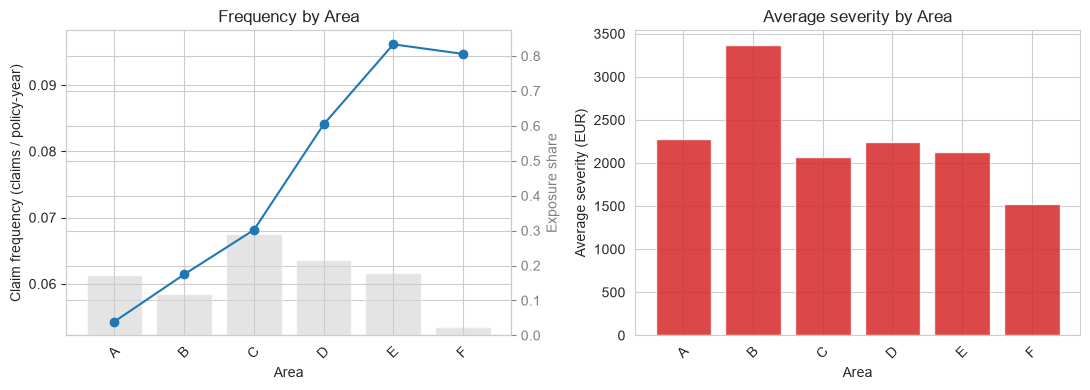

,Area,exposure,claims,frequency,exposure_share,avg_severity
0,A,"60,915.7339",3308,0.0543,0.1723,"2,279.1954"
1,B,"42,344.5102",2601,0.0614,0.1198,"3,369.4286"
2,C,"102,902.3953",7011,0.0681,0.2910,"2,071.9789"
3,D,"76,232.3723",6408,0.0841,0.2156,"2,246.6602"
4,E,"63,162.2377",6074,0.0962,0.1786,"2,128.6385"
5,F,"8,002.6786",758,0.0947,0.0226,"1,525.4117"


In [4]:
freq_area = weighted_frequency_by_factor(df, "Area")
sev_area = severity_by_factor(df, "Area")
plot_frequency_severity_profile(freq_area, sev_area, "Area")
plt.show()
freq_area.merge(sev_area[["Area", "avg_severity"]], on="Area")

**Reading:** frequency rises from Area A (5.4%) to Area E (9.6%), with Area F (9.5%) at the same
level as E. That is what an urban-density proxy should show: denser areas mean more traffic. Severity
does not follow the same pattern (Area B has the highest average severity), an early hint that
frequency and severity are driven by different mechanisms, one reason this project fits separate
frequency and severity models.

### 3.2 `VehGas`: fuel type

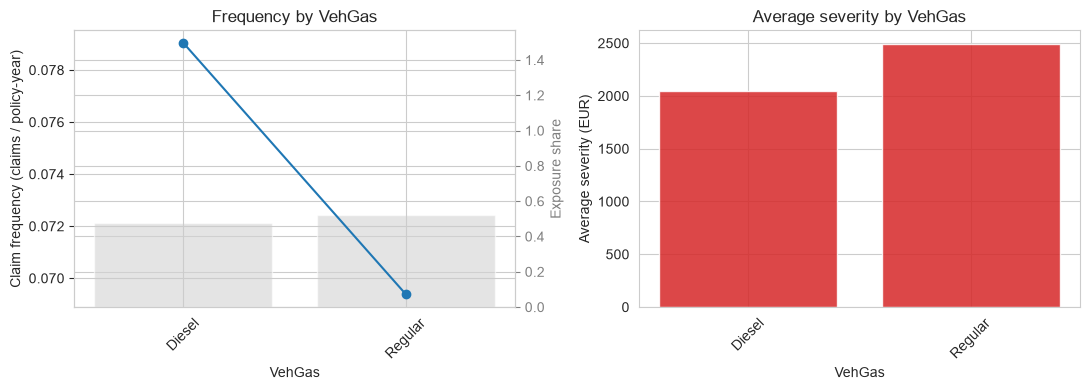

,VehGas,exposure,claims,frequency,exposure_share,avg_severity
0,Diesel,"168,870.7083",13347,0.0790,0.4776,"2,048.5584"
1,Regular,"184,689.2198",12813,0.0694,0.5224,"2,495.2927"


In [5]:
freq_gas = weighted_frequency_by_factor(df, "VehGas")
sev_gas = severity_by_factor(df, "VehGas")
plot_frequency_severity_profile(freq_gas, sev_gas, "VehGas")
plt.show()
freq_gas.merge(sev_gas[["VehGas", "avg_severity"]], on="VehGas")

**Reading:** Diesel shows a higher claim frequency than Regular (7.9% vs. 6.9%), while Regular has
the higher average severity (EUR 2,495 vs. EUR 2,049). Average severity is sensitive to a few very large
claims (see `DrivAge` below), so the severity gap is checked again in Phase 6 with large losses capped.

### 3.3 `VehPower`: fiscal power rating

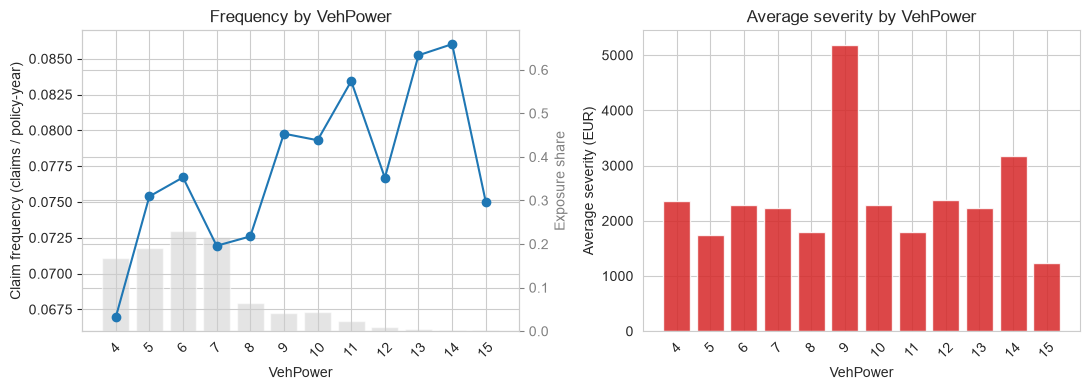

,VehPower,exposure,claims,frequency,exposure_share
0,4,"59,250.6062",3966,0.0669,0.1676
1,5,"67,108.2049",5059,0.0754,0.1898
2,6,"81,352.0918",6241,0.0767,0.2301
3,7,"76,825.2337",5527,0.0719,0.2173
4,8,"22,521.5436",1635,0.0726,0.0637
5,9,"15,106.1581",1205,0.0798,0.0427
6,10,"15,155.6998",1202,0.0793,0.0429
7,11,"8,413.7221",702,0.0834,0.0238
8,12,"3,768.4729",289,0.0767,0.0107
9,13,"1,630.6953",139,0.0852,0.0046


In [6]:
freq_power = weighted_frequency_by_factor(df, "VehPower")
sev_power = severity_by_factor(df, "VehPower")
plot_frequency_severity_profile(freq_power, sev_power, "VehPower")
plt.show()
freq_power

**Reading:** no clean monotonic pattern: frequency moves between roughly 6.7% and 8.6% with no clear
trend, and exposure thins out sharply above power rating 8 (the last four levels together hold under 3%
of exposure). A linear term would force a trend that is not really there; a GAM smooth or coarse bins
can represent "roughly flat with noise in the thin tail".

### 3.4 `VehBrand`

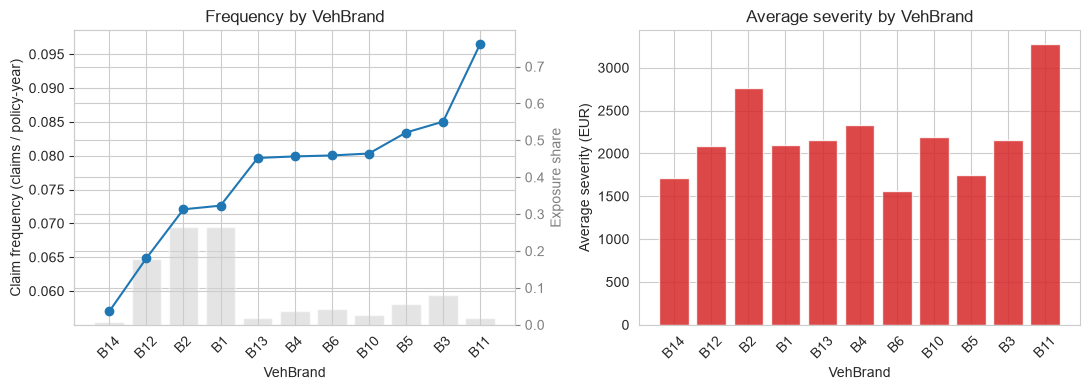

,VehBrand,exposure,claims,frequency,exposure_share,avg_severity
0,B14,"2,246.0523",128,0.0570,0.0064,"1,708.0409"
1,B12,"63,443.1189",4114,0.0648,0.1794,"2,081.9395"
2,B2,"93,539.9434",6742,0.0721,0.2646,"2,762.3923"
3,B1,"94,037.5559",6829,0.0726,0.2660,"2,103.7725"
4,B13,"6,703.1486",534,0.0797,0.0190,"2,156.3630"
5,B4,"13,642.7770",1090,0.0799,0.0386,"2,329.3549"
6,B6,"15,555.2681",1245,0.0800,0.0440,"1,566.9489"
7,B10,"9,436.8487",758,0.0803,0.0267,"2,190.0378"
8,B5,"19,754.6600",1648,0.0834,0.0559,"1,752.9211"
9,B3,"28,352.9680",2411,0.0850,0.0802,"2,150.7424"


In [7]:
freq_brand = weighted_frequency_by_factor(df, "VehBrand").sort_values("frequency")
sev_brand = severity_by_factor(df, "VehBrand")
plot_frequency_severity_profile(freq_brand, sev_brand, "VehBrand")
plt.show()
freq_brand.merge(sev_brand[["VehBrand", "avg_severity"]], on="VehBrand")

**Reading:** the eleven anonymized brands sit between 5.7% and 9.7%. `B12` (18% of exposure) is at
the low end (6.5%), `B11` at the high end (9.7%, on 2% of exposure). A moderate factor, worth testing
in the GLM.

### 3.5 `Region`

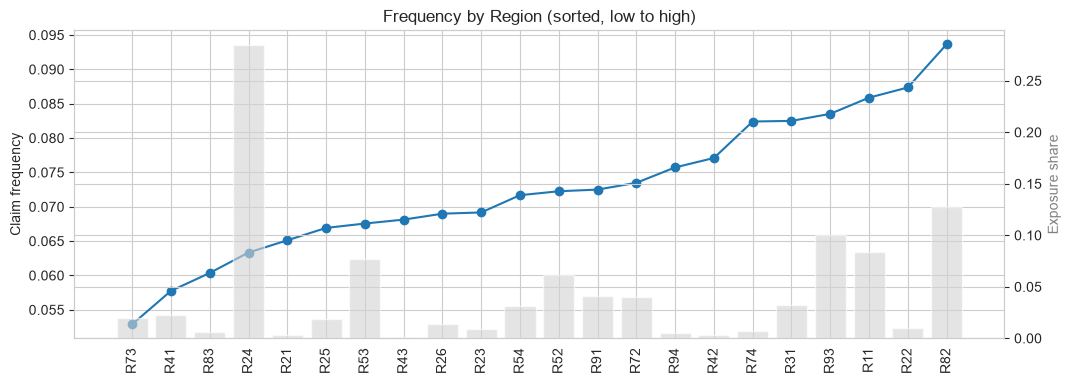

,Region,exposure,claims,frequency,exposure_share
15,R73,"6,920.1440",366,0.0529,0.0196
8,R41,"8,069.1180",466,0.0578,0.0228
18,R83,"2,302.9042",139,0.0604,0.0065
4,R24,"100,684.5760",6377,0.0633,0.2848
1,R21,"1,182.5351",77,0.0651,0.0033
5,R25,"6,530.3275",437,0.0669,0.0185
12,R53,"27,148.3745",1834,0.0676,0.0768
10,R43,557.7847,38,0.0681,0.0016
6,R26,"4,957.2504",342,0.0690,0.0140
3,R23,"3,151.6422",218,0.0692,0.0089


In [8]:
freq_region = weighted_frequency_by_factor(df, "Region").sort_values("frequency")
sev_region = severity_by_factor(df, "Region")
fig, ax = plt.subplots(figsize=(12, 4))
ax2 = ax.twinx()
ax2.bar(freq_region["Region"], freq_region["exposure_share"], color="lightgray", alpha=0.6)
ax.plot(freq_region["Region"], freq_region["frequency"], marker="o", color="#1f77b4")
ax.set_ylabel("Claim frequency"); ax2.set_ylabel("Exposure share", color="gray")
ax.set_title("Frequency by Region (sorted, low to high)")
ax.tick_params(axis="x", rotation=90)
plt.show()
freq_region

**Reading:** a spread of about 1.8x from the lowest region (`R73`, 5.3%) to the highest (`R82`, 9.4%),
with most of the exposure concentrated in a handful of large regions (`R24`, `R82`, `R93`, `R11`).
`R24`, the largest region (28.5% of exposure), is among the lowest-frequency regions. A geographic
signal that plausibly overlaps with `Density`, checked in Section 4.

### 3.6 `VehAge`: vehicle age (binned)

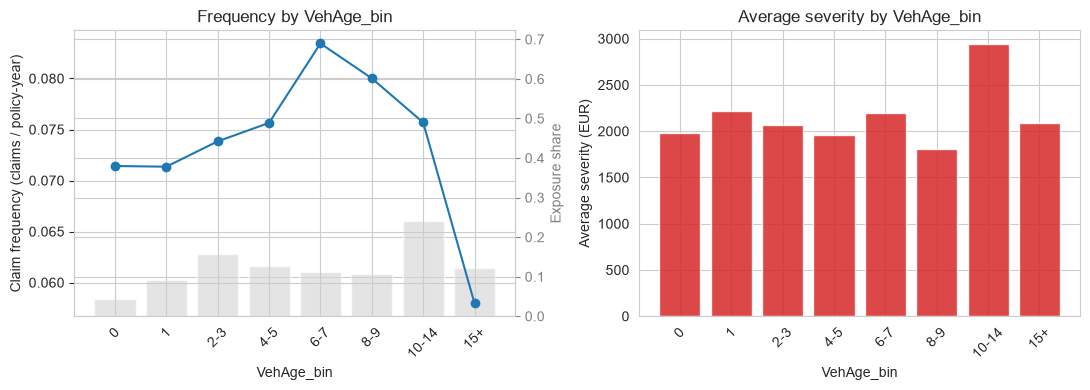

,VehAge_bin,exposure,claims,frequency,exposure_share,avg_severity
0,0,"15,597.1562",1114,0.0714,0.0441,"1,976.4767"
1,1,"32,414.8648",2313,0.0714,0.0917,"2,215.1444"
2,2-3,"55,185.8563",4075,0.0738,0.1561,"2,071.6984"
3,4-5,"45,326.5991",3429,0.0757,0.1282,"1,959.9227"
4,6-7,"39,480.6354",3294,0.0834,0.1117,"2,196.9881"
5,8-9,"37,592.8980",3008,0.0800,0.1063,"1,809.1150"
6,10-14,"85,149.6009",6445,0.0757,0.2408,"2,941.7052"
7,15+,"42,812.3172",2482,0.0580,0.1211,"2,090.0917"


In [9]:
df["VehAge_bin"] = bin_continuous(
    df["VehAge"], bins=[0, 1, 2, 4, 6, 8, 10, 15, 101],
    labels=["0", "1", "2-3", "4-5", "6-7", "8-9", "10-14", "15+"],
)
freq_vehage = weighted_frequency_by_factor(df, "VehAge_bin")
sev_vehage = severity_by_factor(df, "VehAge_bin")
plot_frequency_severity_profile(freq_vehage, sev_vehage, "VehAge_bin")
plt.show()
freq_vehage.merge(sev_vehage[["VehAge_bin", "avg_severity"]], on="VehAge_bin")

**Reading:** a mild hump: frequency rises from about 7.1% for new vehicles to a peak of 8.3% at 6-7
years, then falls to 5.8% for vehicles 15 years and older. The shape is non-linear, which makes
`VehAge` a natural GAM smooth-term candidate (Phase 5). (Before the claims-only block was excluded in
Phase 1, brand-new vehicles showed an apparent frequency spike; that spike came from the block, not
from the insured population.)

### 3.7 `DrivAge`: driver age (binned)

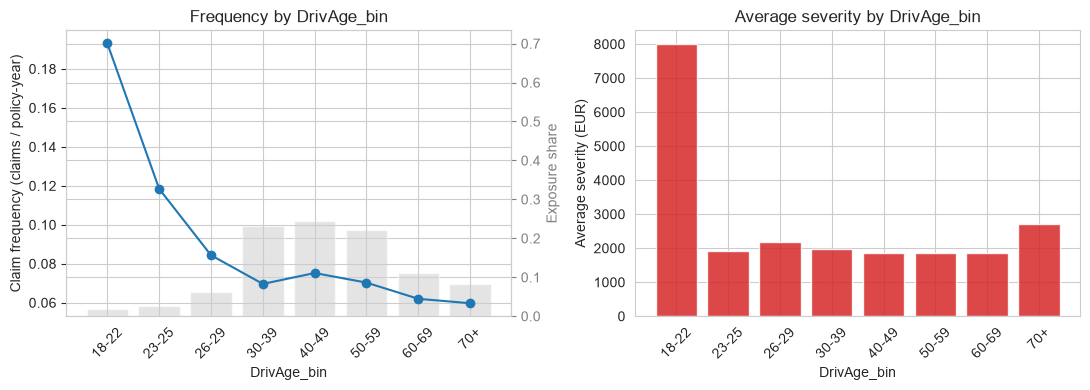

,DrivAge_bin,exposure,claims,frequency,exposure_share,avg_severity
0,18-22,"6,574.0491",1269,0.1930,0.0186,"8,000.8340"
1,23-25,"9,508.4249",1126,0.1184,0.0269,"1,913.1299"
2,26-29,"21,846.7074",1843,0.0844,0.0618,"2,183.6242"
3,30-39,"81,751.2674",5693,0.0696,0.2312,"1,983.3243"
4,40-49,"86,471.2539",6504,0.0752,0.2446,"1,862.1660"
5,50-59,"78,705.4691",5533,0.0703,0.2226,"1,856.5362"
6,60-69,"39,330.0417",2438,0.0620,0.1112,"1,858.7314"
7,70+,"29,372.7145",1754,0.0597,0.0831,"2,724.3714"


In [10]:
df["DrivAge_bin"] = bin_continuous(
    df["DrivAge"], bins=[18, 23, 26, 30, 40, 50, 60, 70, 101],
    labels=["18-22", "23-25", "26-29", "30-39", "40-49", "50-59", "60-69", "70+"],
)
freq_drivage = weighted_frequency_by_factor(df, "DrivAge_bin")
sev_drivage = severity_by_factor(df, "DrivAge_bin")
plot_frequency_severity_profile(freq_drivage, sev_drivage, "DrivAge_bin")
plt.show()
freq_drivage.merge(sev_drivage[["DrivAge_bin", "avg_severity"]], on="DrivAge_bin")

**Reading:** the steepest effect in the dataset: **19.3% frequency for 18-22-year-olds**, more than
twice the portfolio average, falling quickly through the 20s to about 7% for 30-59-year-olds and 6% after
60. The classic new-driver curve, without a second rise for elderly drivers in this portfolio.
`DrivAge` is a strong frequency factor.

**The severity panel needs care:** the 18-22 band's average severity (**EUR 8,001**) looks far higher
than every other band (EUR 1,850-2,750), but this is not a systematic young-driver severity effect. The
*median* claim in that band is EUR 1,172, identical to the portfolio median; the mean is driven by
10 very large claims (out of 1,267 paid claims in the band) that account for about 77% of the band's
claim cost, including the largest claim in the dataset (EUR 4.08M). Mean severity is fragile under a
heavy tail, which is the reason for the large-loss treatment in Phase 6.

### 3.8 `BonusMalus`: no-claims bonus/malus coefficient (binned)

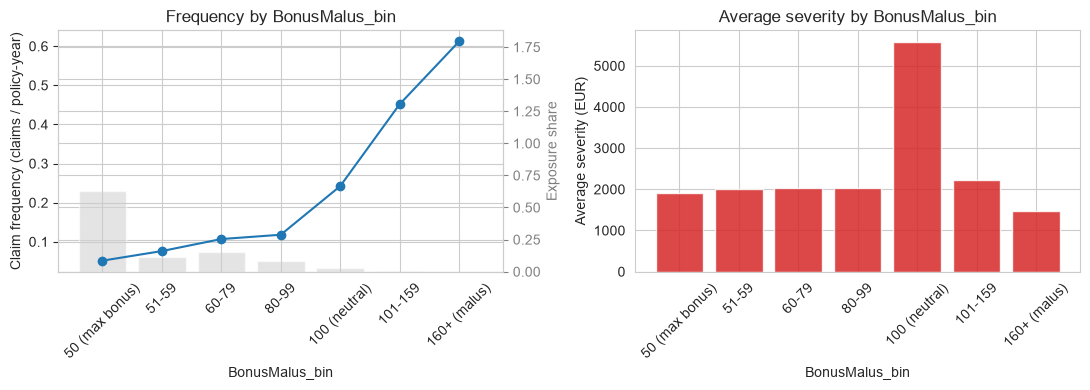

,BonusMalus_bin,exposure,claims,frequency,exposure_share,avg_severity
0,50 (max bonus),"221,523.8530",11420,0.0516,0.6266,"1,915.1287"
1,51-59,"39,481.3520",3004,0.0761,0.1117,"2,001.5384"
2,60-79,"53,338.8437",5699,0.1068,0.1509,"2,039.5110"
3,80-99,"29,550.4525",3482,0.1178,0.0836,"2,037.2056"
4,100 (neutral),"8,664.0808",2098,0.2421,0.0245,"5,579.6247"
5,101-159,971.9460,439,0.4517,0.0027,"2,216.4903"
6,160+ (malus),29.4000,18,0.6122,0.0001,"1,461.9433"


In [11]:
df["BonusMalus_bin"] = bin_continuous(
    df["BonusMalus"], bins=[50, 51, 60, 80, 100, 120, 160, 231],
    labels=["50 (max bonus)", "51-59", "60-79", "80-99", "100 (neutral)", "101-159", "160+ (malus)"],
)
freq_bm = weighted_frequency_by_factor(df, "BonusMalus_bin")
sev_bm = severity_by_factor(df, "BonusMalus_bin")
plot_frequency_severity_profile(freq_bm, sev_bm, "BonusMalus_bin")
plt.show()
freq_bm.merge(sev_bm[["BonusMalus_bin", "avg_severity"]], on="BonusMalus_bin")

**Reading:** the strongest and cleanest monotonic relationship in the dataset: frequency climbs from
**5.2%** at the maximum-bonus floor (`50`, 63% of the portfolio's exposure) to **61%** for the small
malus tail above 160. Expected, since `BonusMalus` is itself built from each driver's own claims
history. In Phase 4 it will likely dominate the GLM, so the other factors are judged on the
*independent* signal they add once `BonusMalus` is in the model (see Section 4).

### 3.9 `Density`: population density (log-scale bins)

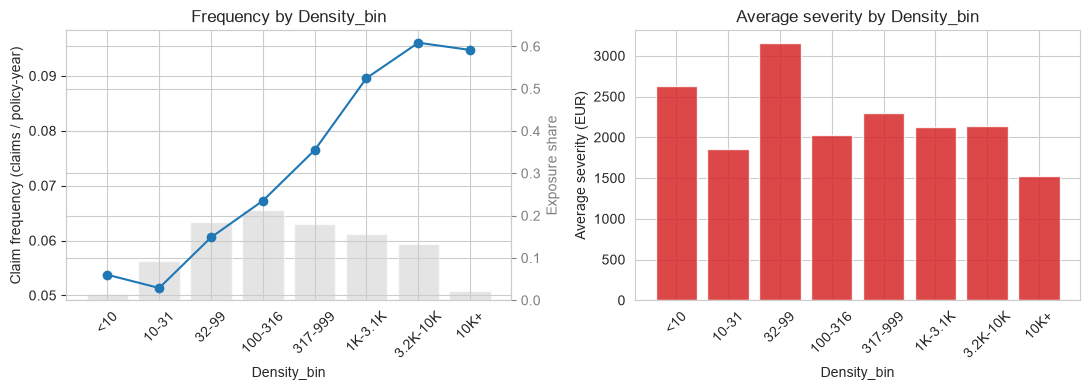

,Density_bin,exposure,claims,frequency,exposure_share,avg_severity
0,<10,"5,171.2653",278,0.0538,0.0146,"2,623.8071"
1,10-31,"33,166.1224",1703,0.0513,0.0938,"1,860.2705"
2,32-99,"65,006.2710",3937,0.0606,0.1839,"3,152.9046"
3,100-316,"75,150.1503",5053,0.0672,0.2126,"2,033.3605"
4,317-999,"64,043.7753",4897,0.0765,0.1811,"2,295.8689"
5,1K-3.1K,"55,754.2033",4995,0.0896,0.1577,"2,132.0303"
6,3.2K-10K,"47,263.3918",4539,0.0960,0.1337,"2,132.4740"
7,10K+,"8,002.6786",758,0.0947,0.0226,"1,525.4117"


In [12]:
df["Density_bin"] = pd.cut(
    np.log10(df["Density"]), bins=[0, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5],
    labels=["<10", "10-31", "32-99", "100-316", "317-999", "1K-3.1K", "3.2K-10K", "10K+"],
)
freq_density = weighted_frequency_by_factor(df, "Density_bin")
sev_density = severity_by_factor(df, "Density_bin")
plot_frequency_severity_profile(freq_density, sev_density, "Density_bin")
plt.show()
freq_density.merge(sev_density[["Density_bin", "avg_severity"]], on="Density_bin")

**Reading:** a monotonic climb from about **5.1-5.4%** in the least-dense areas to about **9.5%** in the
densest, the same story as `Area` in Section 3.1 (see next section). `Density` is a continuous frequency
signal and a natural GAM smooth-term candidate.

## 4. Redundancy check: is `Area` just a discretized `Density`?

`Area` (a 6-level A-F code) and `Density` (a continuous population-density figure) told an almost
identical frequency story above. That is worth checking directly before Phase 4: feeding a GLM two
factors that encode the same information doesn't just waste a factor, it inflates coefficient variance
and makes both estimates less stable and harder to interpret.

In [13]:
density_by_area = df.groupby("Area", observed=True)["Density"].agg(["median", "mean", "count"])
density_by_area

,median,mean,count
Area,,,
A,27.0000,27.5112,102309
B,72.0000,72.5869,74322
C,222.0000,248.8897,189175
D,"1,054.0000","1,075.8267",149700
E,"3,744.0000","4,380.4372",135522
F,"27,000.0000","22,004.7362",17598


**Finding:** `Density`'s median rises **monotonically and dramatically** across `Area` levels.
from 27 inhabitants/km² in Area A to 27,000 in Area F, a 1,000x span with zero overlap in the medians.
`Area` is, for practical purposes, a discretized version of `Density`. **Decision for Phase 3/4:** carry
`Density` (the continuous, more granular version) as the primary factor and treat `Area` as redundant
or use `Area` alone as a simpler, more filing-friendly proxy in the GLM while reserving `Density` for
the GAM, and compare. Either way, the choice is now a documented, evidence-based one instead of an
accident of "both were in the file."

### Correlation among the continuous factors

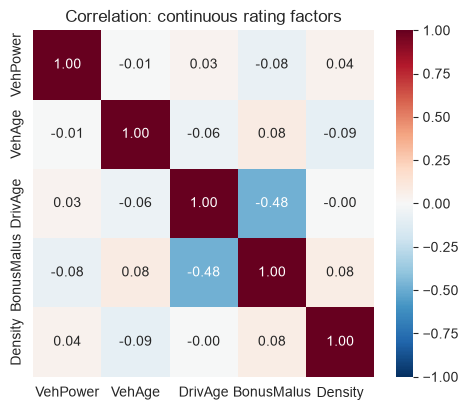

,VehPower,VehAge,DrivAge,BonusMalus,Density
VehPower,1.0000,-0.0071,0.0313,-0.0762,0.0432
VehAge,-0.0071,1.0000,-0.0604,0.0814,-0.0895
DrivAge,0.0313,-0.0604,1.0000,-0.4797,-0.0035
BonusMalus,-0.0762,0.0814,-0.4797,1.0000,0.0769
Density,0.0432,-0.0895,-0.0035,0.0769,1.0000


In [14]:
corr = df[["VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation: continuous rating factors")
plt.show()
corr

**Finding:** every pairwise correlation among the five continuous factors is negligible
(|r| < 0.10) **except one**: `DrivAge` and `BonusMalus` at **r = -0.48**, a moderate negative
correlation. This makes actuarial sense: a young driver has, by construction, had fewer years to
either earn a bonus or accumulate a malus, so `DrivAge` and `BonusMalus` partially encode overlapping
information about driving experience. Not severe enough to drop either factor outright (both showed
strong, distinct-shaped univariate effects above: a sharp young-driver spike for `DrivAge` vs. a
smooth monotonic climb for `BonusMalus`), but flagged here so Phase 4's GLM coefficients for these two
are read with that overlap in mind, and so a variance-inflation-factor check is on the Phase 3
checklist rather than an afterthought.

## Phase 2 summary

| Factor | Frequency signal | Severity signal | Note for modeling |
|---|---|---|---|
| `BonusMalus` | **Very strong**, monotonic (5.2% to 61%) | Moderate | Built from claims history, the strongest predictor |
| `DrivAge` | **Strong**, young-driver spike then flat | Weak (mean distorted by a few large losses) | Correlated with `BonusMalus` (r = -0.48), to watch in Phase 4; severity needs large-loss capping |
| `Density` | Strong, monotonic | Weak/mixed | Continuous version of `Area`: pick one |
| `Area` | Strong, monotonic | Weak/mixed | Redundant with `Density` (Section 4) |
| `VehAge` | Moderate, hump at 6-7 years | Weak | Non-linear: GAM candidate |
| `Region` | Moderate (~1.8x spread) | Mixed | Geographic, plausibly overlapping `Density` |
| `VehBrand` | Moderate | Mixed | Spread of 5.7% to 9.7% |
| `VehGas` | Moderate (Diesel higher) | Moderate (Regular higher, mean only) | Checked again with capped severity in Phase 6 |
| `VehPower` | Weak, non-monotonic | Weak | Candidate for binning or dropping |

**Takeaway:** the strongest frequency drivers (`BonusMalus`, `DrivAge`, `Density`/`Area`) are not the
strongest severity drivers, which supports building **separate frequency and severity models** in
Phases 4-6.

**Next:** [Phase 3: data preparation and train/test design](../docs/PROJECT_ROADMAP.md) turns these
findings into an encoding plan and a leak-free train/validation/test split.